# Adding photometry

Sometimes, we want to conjunctionally use some photometry data in addition to the interferometric data. For instance, you may have high-resolution ALMA data and low-resolution e.g., VLA and/or single dish data.

First, we prepare the module and ALMA data as usual.

In [1]:
import frap
import pickle
import numpy as np
import jax.numpy as jnp
import dsharp_opac
import matplotlib.pyplot as plt
import numpyro

numpyro.set_host_device_count(10)

bands = ['band3', 'band6']
files = {'band3': 'HD169142_band3.pkl',
         'band6': 'HD169142_band6.pkl'}

obs = {}
for band in bands:
    with open(files[band], 'rb') as f:
        obs[band] = pickle.load(f)

dust_opacity = jnp.load(dsharp_opac.get_datafile('default_opacities_smooth.npz'))


According to van der Wiel et al. (2014), the total flux at ~800 GHz measured by Herschel is ~4.0 Jy, and we want to include this.
Note that if you want to multiple points then you can just do it by adding values to the array.

In [2]:
nu_ph = np.array( [800.0] ) * 1e9 # Hz
F_ph = np.array([4.0]) # Jy
s_ph = np.array([0.8]) # Jy

## 2. Add photometry to the disk model

The first part is the same as before, and now you have `set_photometry()` to set the VLA data. Since we have an additional data point, now let's try to include the temperature as a new free parameter.

In [3]:
disk = frap.model(incl=6.28, pa=6.3, r_out=1.3, N_GP=130)

D = 114.9 # pc

# TIP: you can access to the radial grid by this, and set radially dependent bounds.
R = disk.R*D
Tmin = jnp.log10(77*(R/10)**(-0.5)/5)
Tmax = jnp.log10(77*(R/10)**(-0.5)*5)


lengthscale = 0.03

disk.set_parameter('log10_T',
                        free = True,
                        bounds = ( Tmin, Tmax ), 
                        lengthscale = lengthscale )

disk.set_parameter('q',
                   free = False,
                   profile = lambda r: 3.5 )

disk.set_parameter('log10_Sigma_d', 
                   free = True,
                   bounds = ( -6.0, 3.0 ),
                   lengthscale = lengthscale)

disk.set_parameter('log10_a_max', 
                   free = True,
                   bounds =  ( -2.0, 2.0 ),
                   lengthscale = lengthscale)

f_s = {'band3': 0.025, 'band6': 0.05}
for band in bands:
    disk.set_visibility(band=band, 
                        q=obs[band]['q'], 
                        V=obs[band]['V'], 
                        s=obs[band]['s'], 
                        nu=obs[band]['nu'], 
                        Nch=obs[band]['Nch'], 
                        f_s=f_s[band], 
                        f_mean=1.0)

# here we set the photometry data
disk.set_photometry('Herschel',
                    F=F_ph,
                    s=s_ph,
                    nu=nu_ph)

disk.set_opacity(dust_opacity)


In [4]:
disk.summary()

FRAP model summary

[Model]
  Inclination      : 6.280 deg
  Position angle   : 6.300 deg
  Radial grid      : FB, N=130, r_out=1.3 arcsec
  Radial range     : 0.007611 - 1.29 arcsec
  Jitter           : 0.0001
  GP hyperparams   : fixed
  Flux uncertainty : True

[Emission]
  Intensity  : f_I_SL20
  Visibility : None
  Opacity    : configured (Na=1000, Nq=1000, smooth=True)

[Parameters]  3 free, 1 fixed, 390 latent variables
  log10_T           : GP, bounds=profile: lower shape=(130,), range=[0.6021, 1.717], upper shape=(130,), range=[2, 3.115], lengthscale=0.03 arcsec
  log10_Sigma_d     : GP, bounds=(-6, 3), lengthscale=0.03 arcsec
  log10_a_max       : GP, bounds=(-2, 2), lengthscale=0.03 arcsec
  q                 : fixed, 3.5

[Observations]
  Band      Type        Nch  Frequency [GHz]       Ndata
  band3     visibility    2  91.565-103.565          257
  band6     visibility    4  218.096-234.096         948
  Herschel  photometry    1  800.000                   1


'FRAP model summary\n==================\n\n[Model]\n  Inclination      : 6.280 deg\n  Position angle   : 6.300 deg\n  Radial grid      : FB, N=130, r_out=1.3 arcsec\n  Radial range     : 0.007611 - 1.29 arcsec\n  Jitter           : 0.0001\n  GP hyperparams   : fixed\n  Flux uncertainty : True\n\n[Emission]\n  Intensity  : f_I_SL20\n  Visibility : None\n  Opacity    : configured (Na=1000, Nq=1000, smooth=True)\n\n[Parameters]  3 free, 1 fixed, 390 latent variables\n  log10_T           : GP, bounds=profile: lower shape=(130,), range=[0.6021, 1.717], upper shape=(130,), range=[2, 3.115], lengthscale=0.03 arcsec\n  log10_Sigma_d     : GP, bounds=(-6, 3), lengthscale=0.03 arcsec\n  log10_a_max       : GP, bounds=(-2, 2), lengthscale=0.03 arcsec\n  q                 : fixed, 3.5\n\n[Observations]\n  Band      Type        Nch  Frequency [GHz]       Ndata\n  band3     visibility    2  91.565-103.565          257\n  band6     visibility    4  218.096-234.096         948\n  Herschel  photometry 

## 3. Run MCMC

In [6]:
inference = frap.inference(disk)
result = inference.MCMC(num_warmup=2000, num_samples=1000, num_chains=10, seed=1)

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

... (11 outputs left out)

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]


                            mean       std    median      5.0%     95.0%     n_eff     r_hat
    g_f_scale_Herschel      0.13      1.02      0.12     -1.56      1.74    124.41      1.06
       g_f_scale_band3      1.53      0.86      1.54      0.14      2.97     52.78      1.09
       g_f_scale_band6     -3.82      0.46     -3.82     -4.58     -3.06     55.75      1.09
  g_log10_Sigma_d_z[0]      0.87      0.03      0.87      0.83      0.91    451.77      1.02
  g_log10_Sigma_d_z[1]     -2.64      0.50     -2.61     -3.42     -1.79    588.75      1.02
  g_log10_Sigma_d_z[2]     -0.69      0.96     -0.65     -2.09      0.90     76.07      1.08
  g_log10_Sigma_d_z[3]     -0.49      0.88     -0.48     -1.94      0.96     69.62      1.07
  g_log10_Sigma_d_z[4]     -0.57      0.91     -0.55     -2.03      0.94     45.49      1.09
  g_log10_Sigma_d_z[5]     -0.46      0.94     -0.46     -2.11      0.97     39.91      1.11
  g_log10_Sigma_d_z[6]      0.20      0.93      0.23     -1.30      1

## 4. Inspect the results

saved keys:  dict_keys(['warmup_f', 'posterior_f', 'warmup_g', 'posterior_g'])


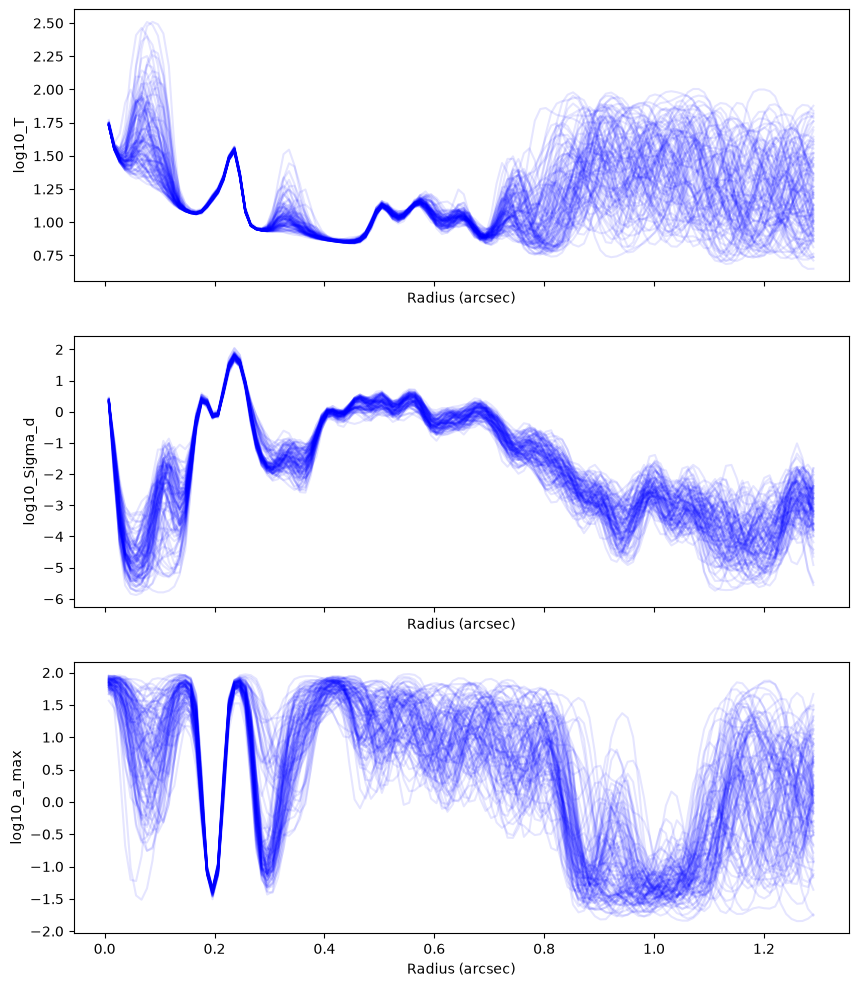

In [7]:
plotter = frap.plot( result )
plotter.sample_paths( 'posterior_f', nskip = 100, plot_kwargs = { 'alpha' : 0.1, 'color' : 'b' } )